# WIDER FACE group-photo detection benchmark

Saved baseline, development tuning, and frozen holdout comparison. This evaluates finding faces, not recognizing identities or redaction correctness.

Recreate the study from the repository root:
```powershell
& .venv/Scripts/python.exe src/scripts/benchmark_widerface.py
```
Reuse complete predictions without new inference:
```powershell
& .venv/Scripts/python.exe src/scripts/benchmark_widerface.py --evaluate-only
```

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
ROOT = Path.cwd()
if not (ROOT / 'src').exists(): ROOT = ROOT.parent
RESULTS = ROOT / 'reports/widerface'
assert (RESULTS / 'report.md').exists(), 'Benchmark is still running or has not been evaluated'
display(Markdown((RESULTS / 'report.md').read_text(encoding='utf-8')))

# WIDER FACE group-photo detection benchmark

Validated 3,226 photos. Final analysis: 2,583 development / 290 untouched holdout / 353 smoke-related QA exclusions.

The original grouped split had 643 holdout photos. The 50-image smoke sample included 12 of them. Before candidate selection or final holdout scoring, we excluded all 353 held-out photos sharing a frozen scene/dHash group with the smoke sample, leaving 290 untouched holdout photos. Development membership and the precision target did not change. This reduces test coverage; the final holdout should not be treated as representative of all WIDER events.

This evaluates face detection, not identity recognition. The app's configuration is unchanged.

Development selection: maximize recall with precision >= 95%. Target met: **True**.

## Frozen holdout comparison

| Configuration | Input / cutoff | Recall | Precision | Missed faces | Unmatched detections | Complete photos | Median / p95 ms* |
|---|---|---:|---:|---:|---:|---:|---:|
| baseline | 1024 / 0.35 | 89.28% | 86.72% | 382 | 487 | 64.48% | 227.7 / 348.1 |
| selected | 1280 / 0.55 | 77.40% | 97.15% | 805 | 81 | 54.48% | 338.6 / 537.1 |

Holdout change: recall -11.88 percentage points; precision +10.43 percentage points; missed faces +423; unmatched detections -406.

The precision-constrained choice misses MORE eligible faces than the original setting. It is a precision/recall tradeoff, not an overall improvement or evidence of redaction readiness. A privacy-focused product needs a separately specified miss tolerance and further validation.

*Timing includes JPEG decode and detection at a shared 0.02 candidate floor, before filtering scores to each cutoff. It excludes embeddings, cloud, redaction and startup. Confidence changes share cached timings, not newly measured production latency.

## Full-validation AP (protocol port)

| Configuration | Easy AP | Medium AP | Hard AP |
|---|---:|---:|---:|
| baseline | 0.9337 | 0.9303 | 0.8854 |
| selected | 0.9184 | 0.9230 | 0.8878 |

AP uses official difficulty masks, inclusive IoU 0.5, global min/max score normalization, 1,000 thresholds and the VOC precision envelope, via a NumPy port tested against an independent scalar reference. This is not an official-server submission or a MATLAB execution. Predictions below raw confidence 0.02 are absent. AP is computed from low-floor ranked predictions, not only detections above the selected operating cutoff. Full-validation AP after tuning is descriptive; the holdout comparison is the selection-independent result.

## Operational scoring and limitations

- Custom metrics use continuous IoU >=0.5 against positive-area, invalid==0 annotations inside the official Hard mask. Other GT boxes are ignored; duplicate detections count as unmatched.
- Crowd count uses all valid annotated faces; complete-photo rate only includes photos with eligible faces. It is not a guarantee that every real person was found.
- Zero-size placeholder annotations occur. Metrics excluding zero-eligible photos are saved separately; predictions without a matching annotation are scored unmatched, not human-confirmed hallucinations.
- Original annotations contain 11 nonpositive boxes and 1 TXT/MAT discrepancy. MAT coordinates/masks are authoritative for AP; invalid geometry is excluded from custom metrics.
- Scene-prefix and dHash grouping reduce duplicate leakage but cannot establish identity-disjoint or fully independent event splits.
- SCRFD is commonly benchmarked/trained on WIDER FACE; the exact pinned checkpoint's image-level training overlap has not been independently established.
- Failed inference aborts the run rather than silently omitting difficult photos. All 3,226 predictions per resolution are required.
- The LFW 0.234 recognition threshold and gallery margin are not used or tuned here.

## Files and reproduction

See docs/widerface_benchmark.md. development_grid.csv records all 15 candidates; selection.json freezes the rule and candidate before holdout scoring. configuration_comparison.csv and the per-image/crowd/size/occlusion tables support tracking. Dataset/model/prediction hashes and versions are in reproducibility.json. Official-format prediction text is under data/benchmarks/widerface/official_predictions/ for independent MATLAB reevaluation.


## Configuration choice

The grid is scored on development images only. Selection is frozen before holdout scoring. If no configuration passes 95% precision, the comparison is an exploratory F1 diagnostic rather than a passing recommendation.

In [2]:
selection = json.loads((RESULTS / 'selection.json').read_text())
print(json.dumps(selection, indent=2))
display(pd.read_csv(RESULTS / 'development_grid.csv'))
display(pd.read_csv(RESULTS / 'configuration_comparison.csv'))

,size,threshold,images,eligible_faces,true_positives,false_positives,false_negatives,complete_photos,eligible_photos,ignored_predictions,precision,recall,f1,complete_photo_rate,false_positives_per_image,median_ms,p95_ms
0,640,0.15,2583,24241,19726,20684,4515,1867,2578,858,0.488146,0.813745,0.610230,0.724205,8.007743,126.2788,144.77771
1,640,0.25,2583,24241,18805,6568,5436,1827,2578,571,0.741142,0.775752,0.758052,0.708689,2.542780,126.2788,144.77771
2,640,0.35,2583,24241,17472,2563,6769,1781,2578,321,0.872074,0.720762,0.789231,0.690846,0.992257,126.2788,144.77771
3,640,0.45,2583,24241,15908,1049,8333,1722,2578,129,0.938138,0.656244,0.772270,0.667960,0.406117,126.2788,144.77771
4,640,0.55,2583,24241,14145,408,10096,1640,2578,33,0.971965,0.583516,0.729236,0.636152,0.157956,126.2788,144.77771
5,1024,0.15,2583,24241,21530,23476,2711,1907,2578,2786,0.478381,0.888165,0.621832,0.739721,9.088657,320.4119,353.13115
6,1024,0.25,2583,24241,20761,7915,3480,1831,2578,2311,0.723985,0.856442,0.784663,0.710240,3.064266,320.4119,353.13115
7,1024,0.35,2583,24241,19873,3294,4368,1769,2578,1718,0.857815,0.819809,0.838382,0.686191,1.275261,320.4119,353.13115
8,1024,0.45,2583,24241,18652,1405,5589,1702,2578,1128,0.929950,0.769440,0.842115,0.660202,0.543941,320.4119,353.13115
9,1024,0.55,2583,24241,17020,574,7221,1600,2578,602,0.967375,0.702116,0.813673,0.620636,0.222222,320.4119,353.13115


,policy,size,threshold,images,eligible_faces,true_positives,false_positives,false_negatives,complete_photos,eligible_photos,ignored_predictions,precision,recall,f1,complete_photo_rate,false_positives_per_image,median_ms,p95_ms
0,baseline,1024,0.35,290,3562,3180,487,382,187,290,265,0.867194,0.892757,0.879790,0.644828,1.67931,227.73015,348.091740
1,selected,1280,0.55,290,3562,2757,81,805,158,290,117,0.971459,0.774003,0.861563,0.544828,0.27931,338.63730,537.094295


{
  "precision_target": 0.95,
  "baseline": {
    "size": 1024,
    "threshold": 0.35
  },
  "sizes": [
    640,
    1024,
    1280
  ],
  "thresholds": [
    0.15,
    0.25,
    0.35,
    0.45,
    0.55
  ],
  "selection_rule": "Max development recall subject to precision target; ties by lower median latency, higher precision, higher threshold",
  "selected_configuration": {
    "size": 1280,
    "threshold": 0.55
  },
  "target_met": true,
  "selection_data": "development only",
  "holdout_audit": {
    "original_holdout_images": 643,
    "smoke_images_in_original_holdout": 12,
    "excluded_smoke_related_images": 353,
    "final_holdout_images": 290,
    "rule": "Exclude originally held-out scene/dHash groups containing any smoke-inspected photo; development unchanged",
    "reason": "QA sample included original holdout photos. Correction made before candidate selection or final holdout scoring."
  },
  "dataset_manifest_sha256": "f074dadba1bdec32270b3e84d5d846af55d12a3cd655091acf39

## Detection PR and speed tradeoffs

Full-validation AP is a NumPy implementation of the supplied MATLAB protocol, not an official-server result. Low-floor latency excludes embeddings, cloud calls and redaction. Confidence-only changes share cached timings.

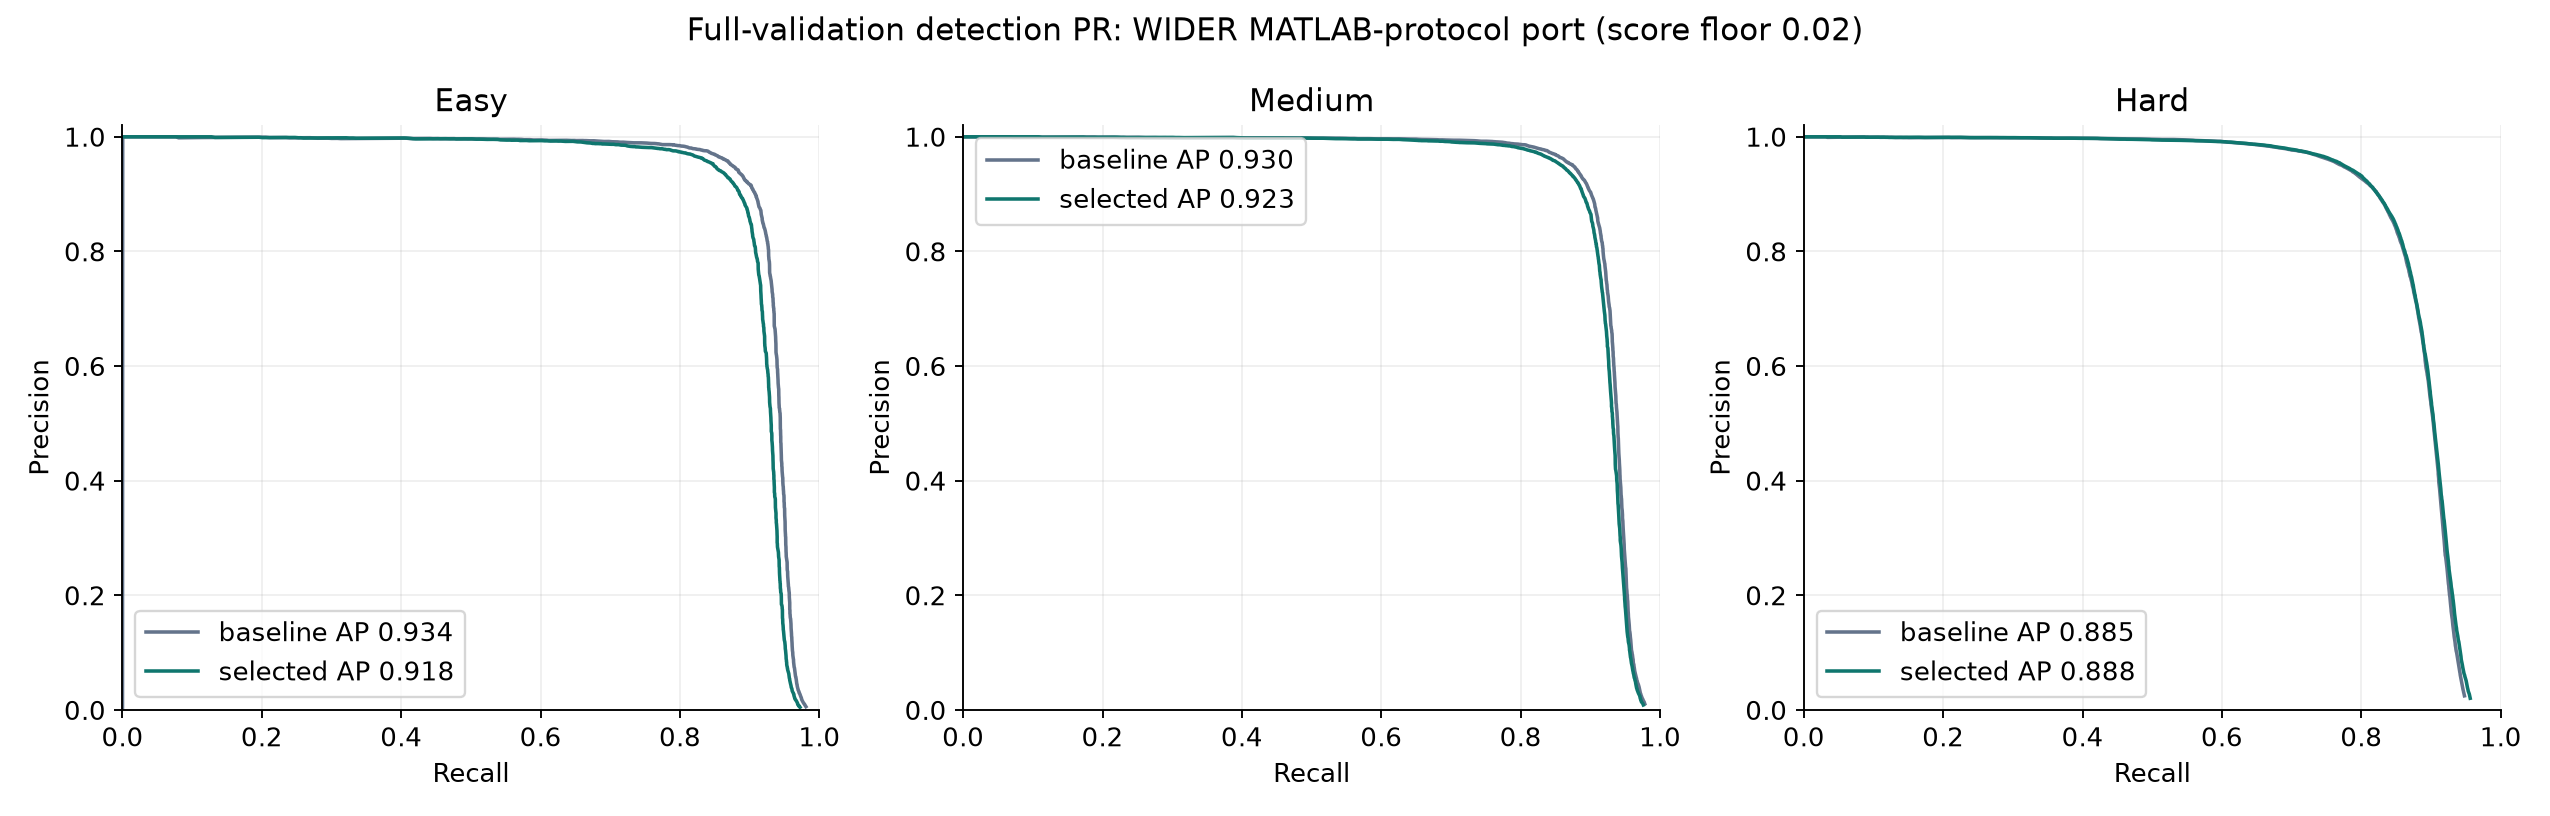

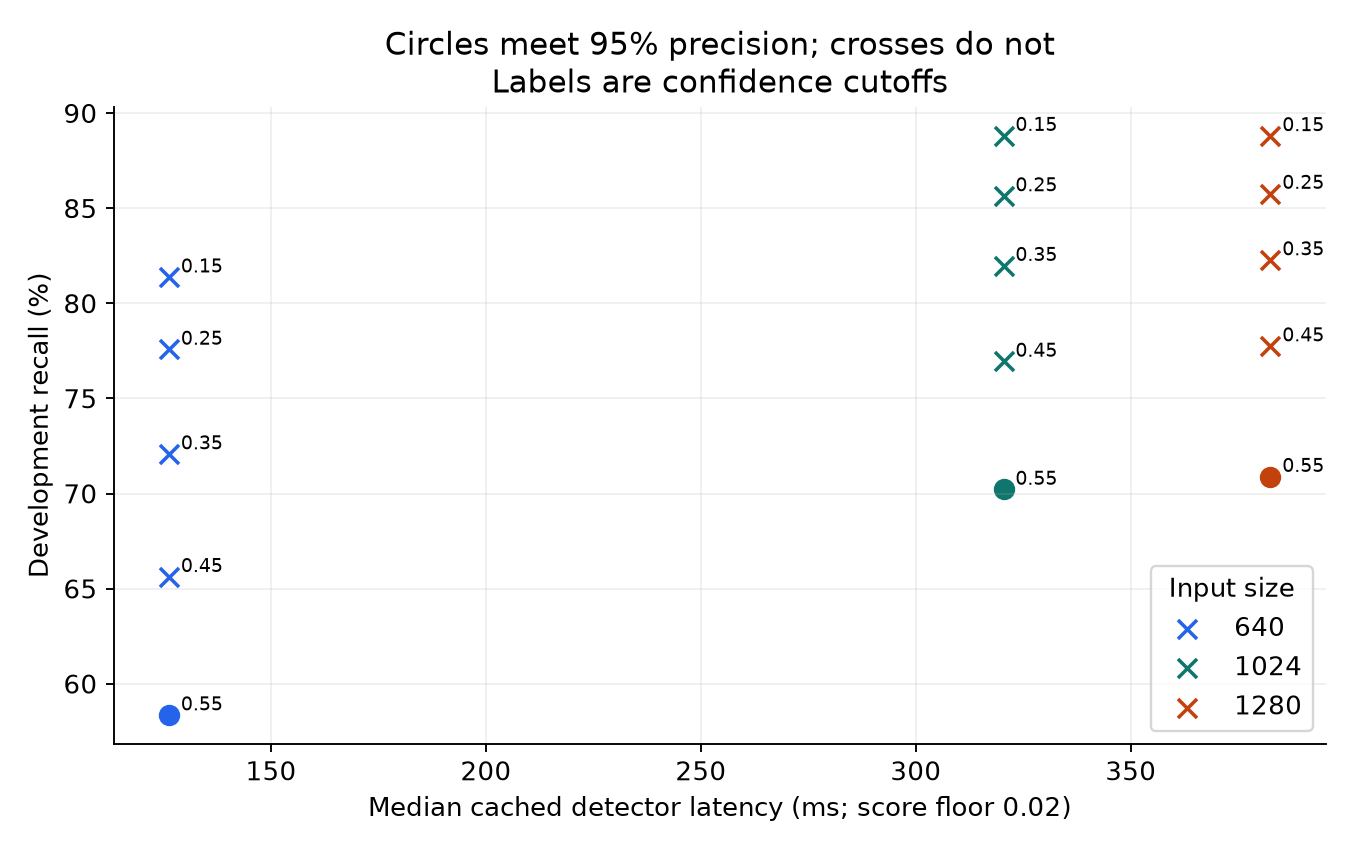

In [3]:
display(Image(filename=str(RESULTS / 'precision_recall.png')))
display(Image(filename=str(RESULTS / 'recall_vs_latency.png')))

## Crowd size, small faces, and occlusion

Complete-photo detection requires every eligible annotation to be matched. It is more demanding than average per-face recall. Ground truth is the valid, positive-area intersection of the official Hard subset.

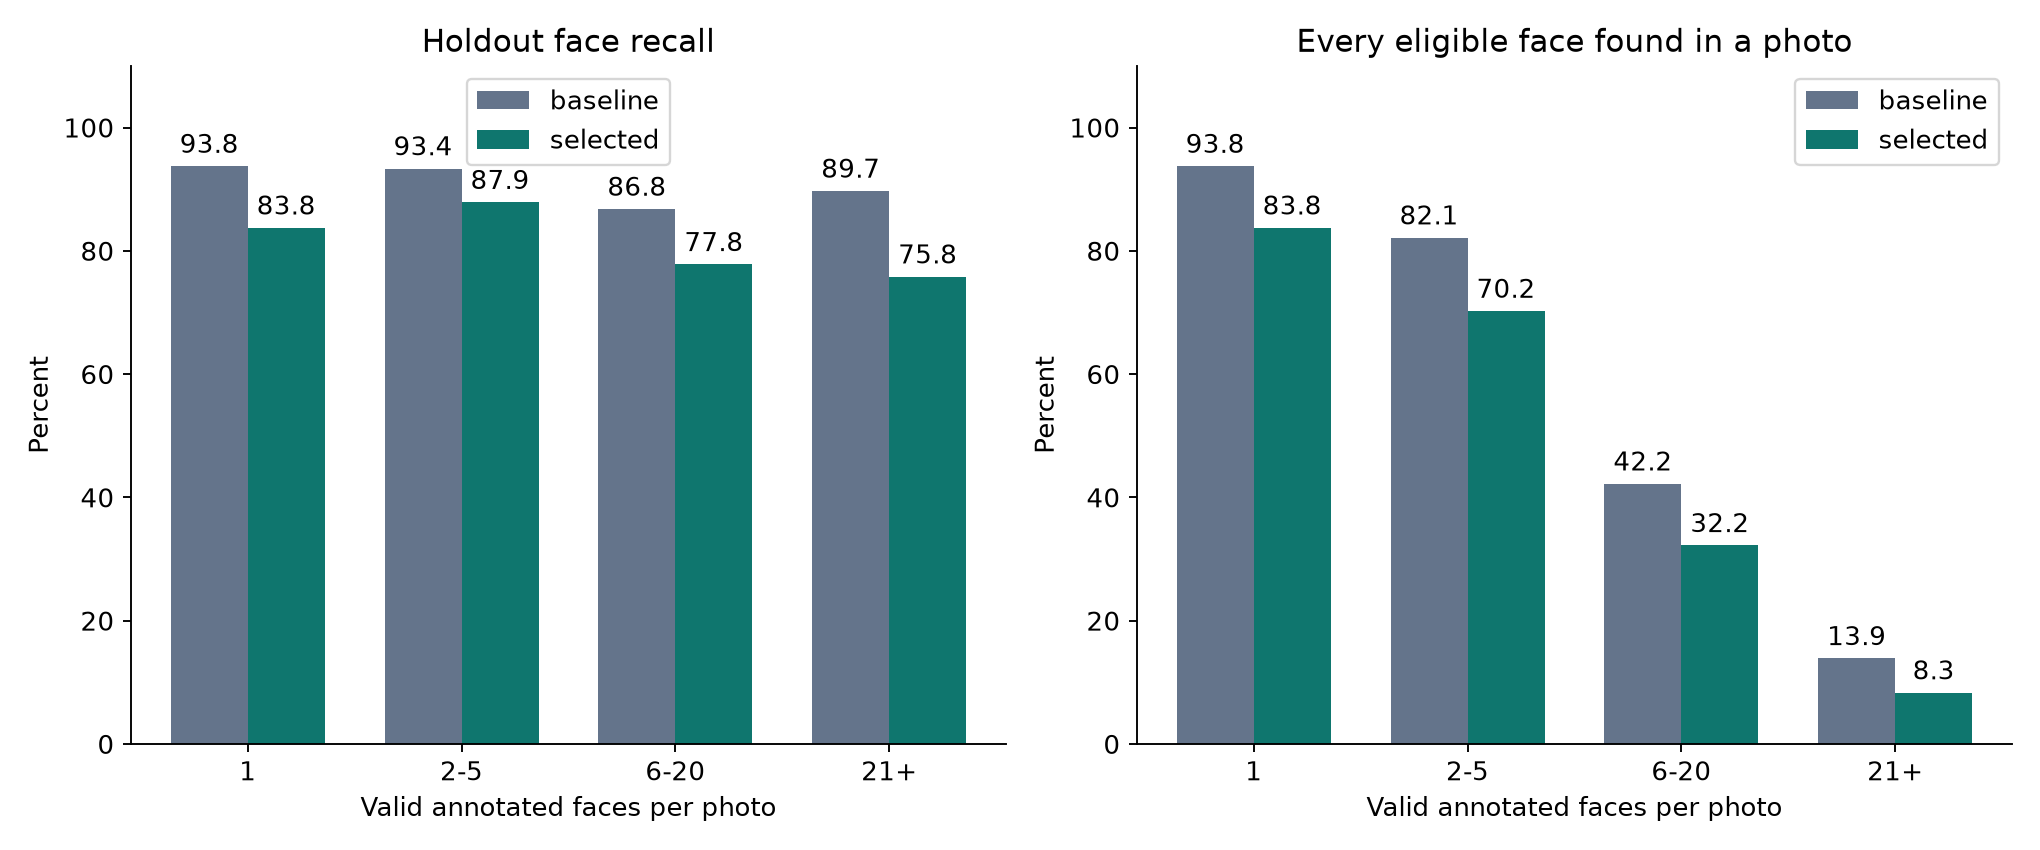

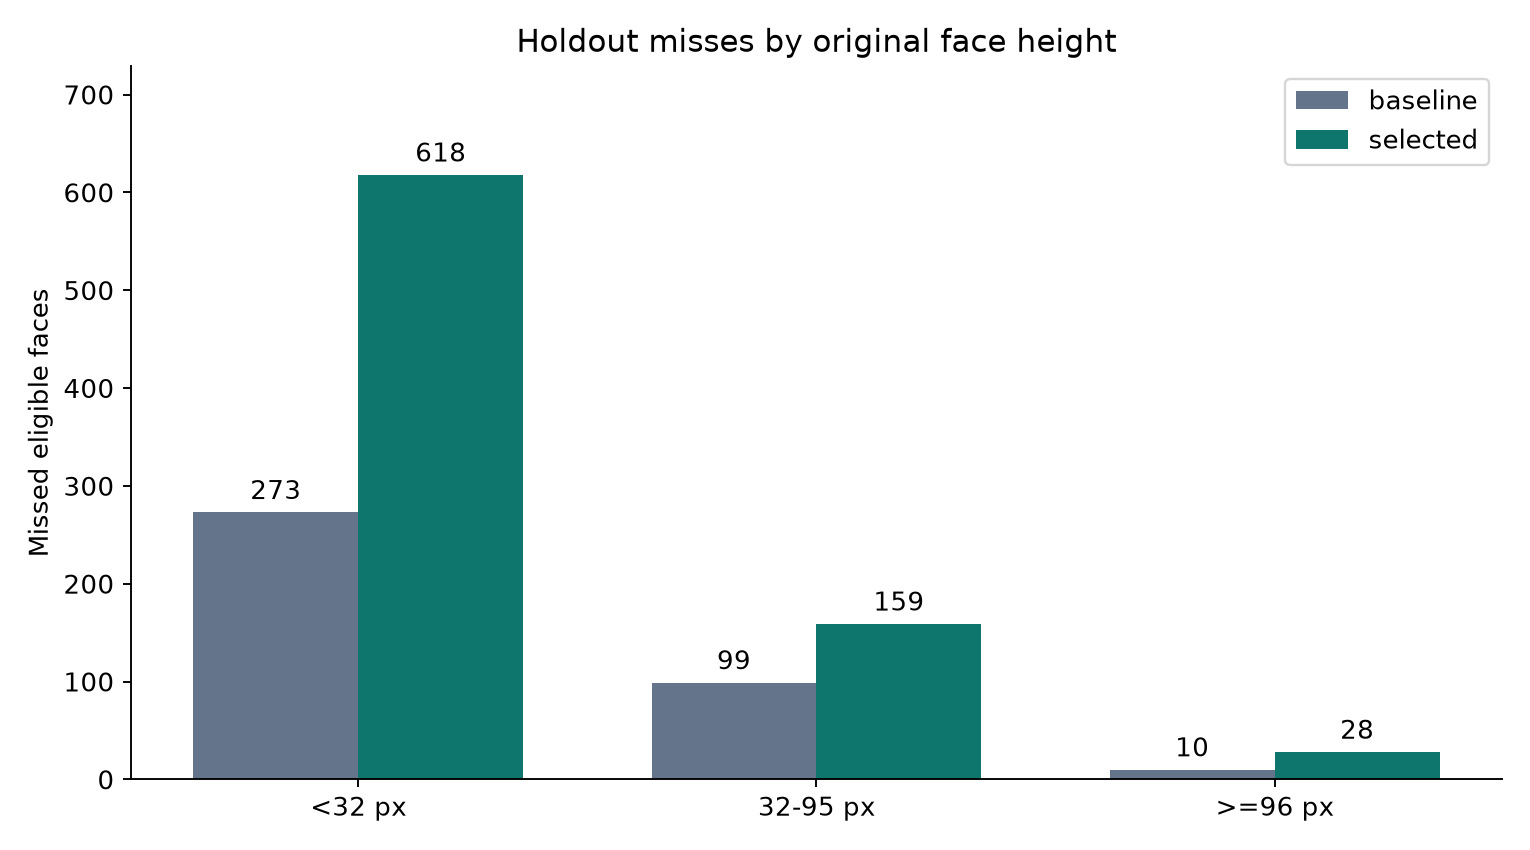

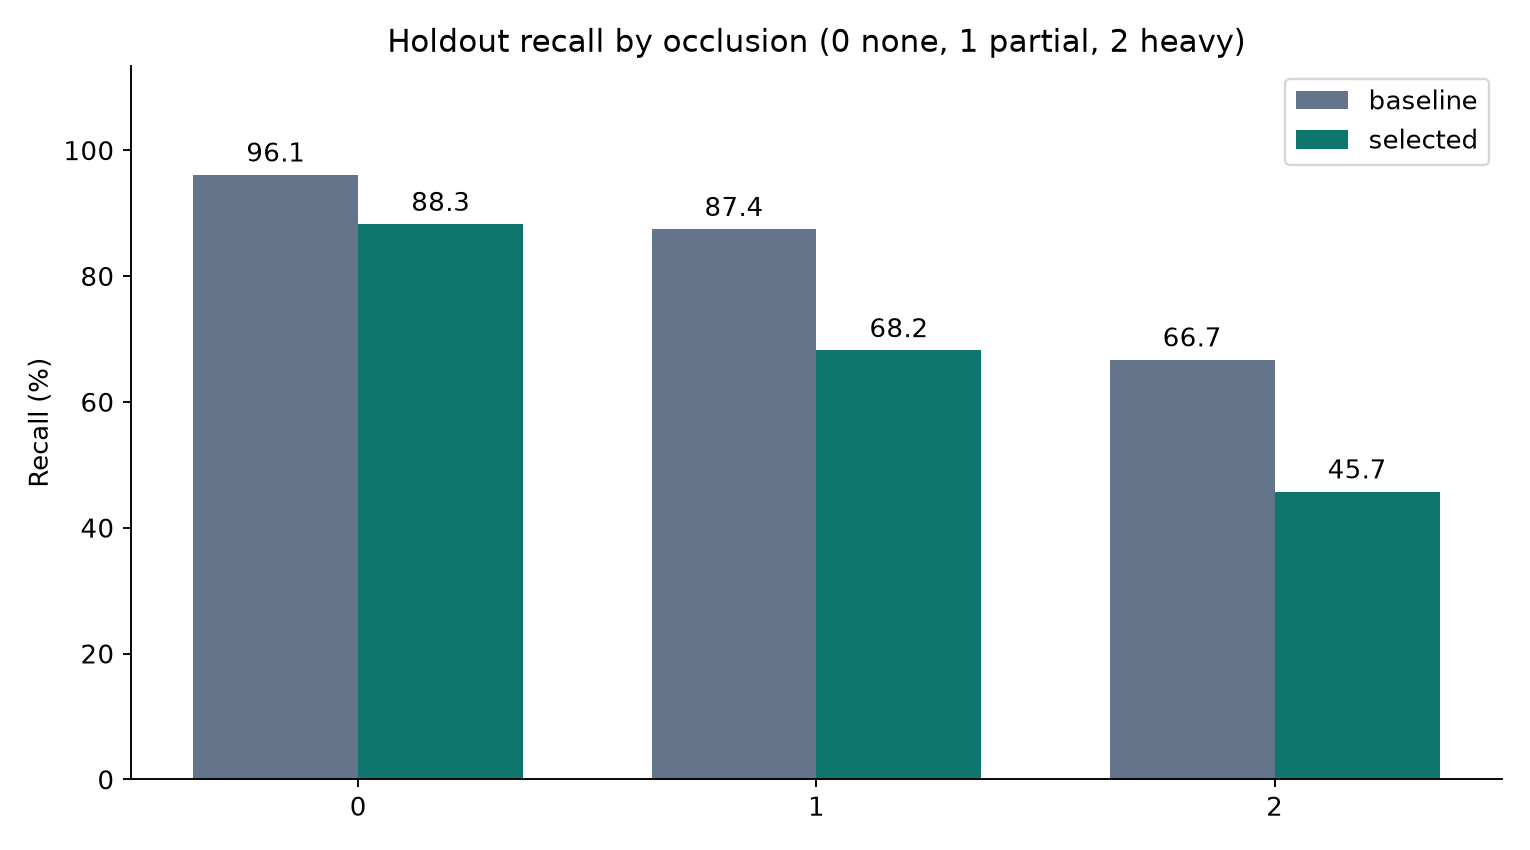

,policy,crowd,images,eligible_faces,true_positives,false_positives,false_negatives,complete_photos,eligible_photos,ignored_predictions,precision,recall,f1,complete_photo_rate,false_positives_per_image,median_ms,p95_ms
0,baseline,1,80,80,75,8,5,75,80,0,0.903614,0.937500,0.920245,0.937500,0.100000,230.33610,339.012035
1,baseline,2-5,84,256,239,38,17,69,84,1,0.862816,0.933594,0.896811,0.821429,0.452381,228.26355,346.952050
2,baseline,6-20,90,969,841,104,128,38,90,11,0.889947,0.867905,0.878788,0.422222,1.155556,215.65030,348.091740
3,baseline,21+,36,2257,2025,337,232,5,36,253,0.857324,0.897209,0.876813,0.138889,9.361111,244.82700,389.477400
4,selected,1,80,80,67,1,13,67,80,0,0.985294,0.837500,0.905405,0.837500,0.012500,339.25605,539.576835
5,selected,2-5,84,256,225,10,31,59,84,0,0.957447,0.878906,0.916497,0.702381,0.119048,330.55000,536.734240
6,selected,6-20,90,969,754,24,215,29,90,7,0.969152,0.778122,0.863194,0.322222,0.266667,338.46645,535.473000
7,selected,21+,36,2257,1711,46,546,3,36,110,0.973819,0.758086,0.852516,0.083333,1.277778,375.29215,548.713000


In [4]:
display(Image(filename=str(RESULTS / 'complete_photo_detection.png')))
display(Image(filename=str(RESULTS / 'missed_faces_by_size.png')))
display(Image(filename=str(RESULTS / 'occlusion_recall.png')))
display(pd.read_csv(RESULTS / 'crowd_count_metrics.csv'))

## Diagnostic examples

Green boxes are eligible annotations; red boxes are detections. These are selected difficult holdout examples, not a representative subset for calculating scores.

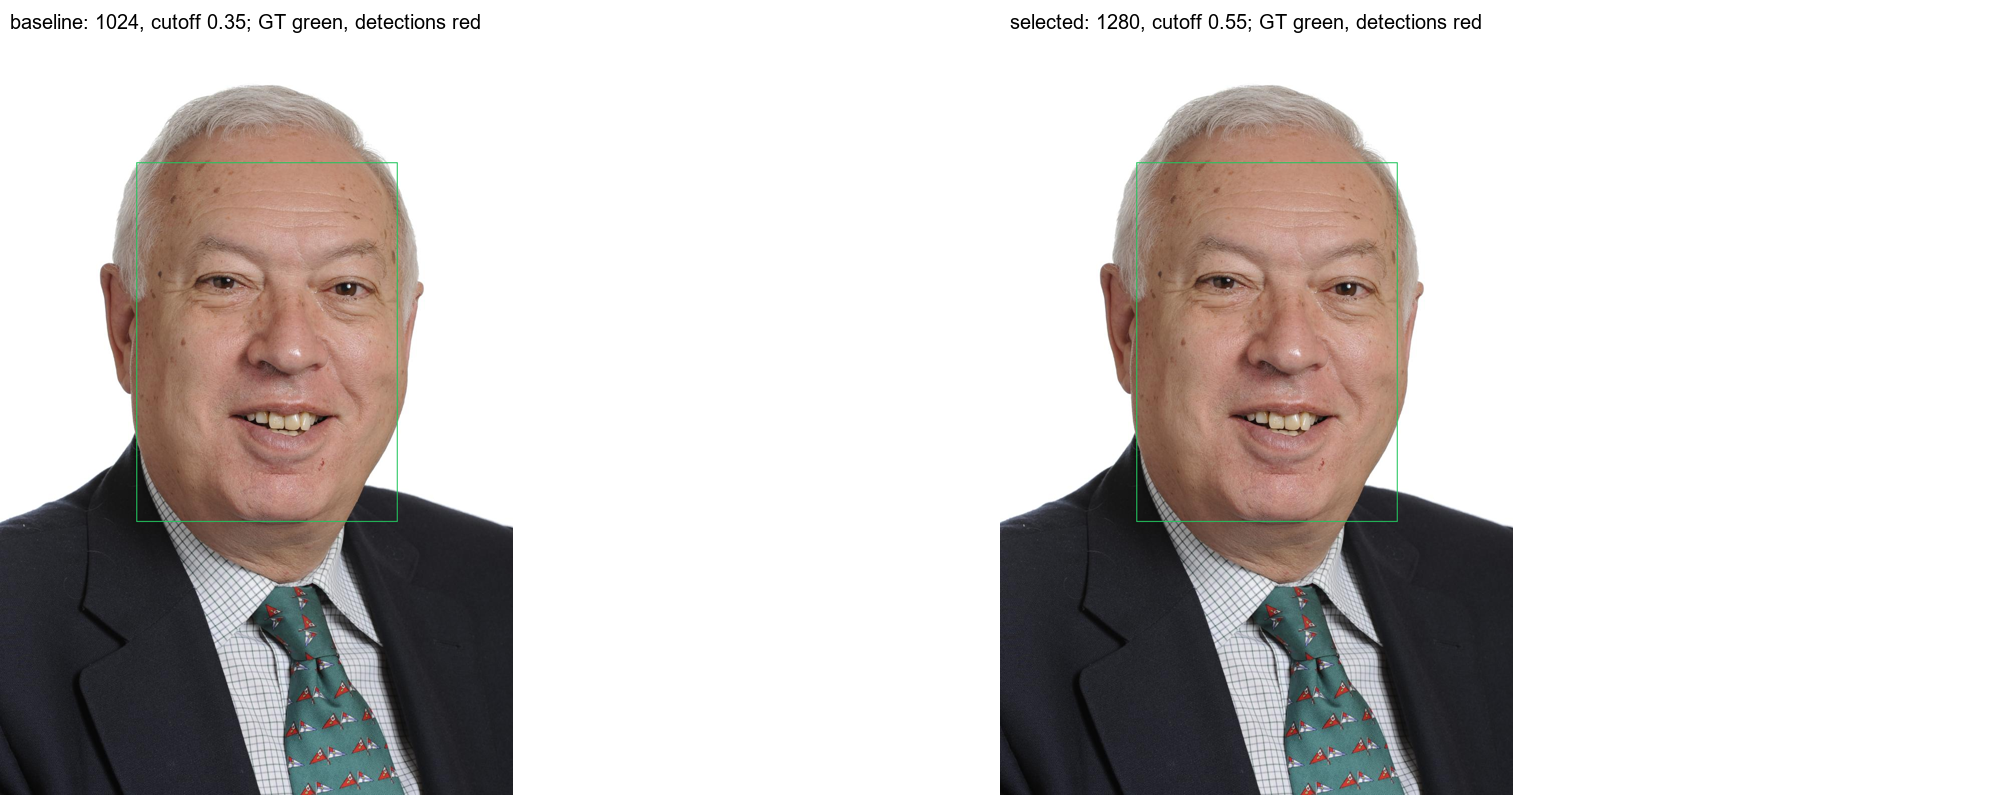

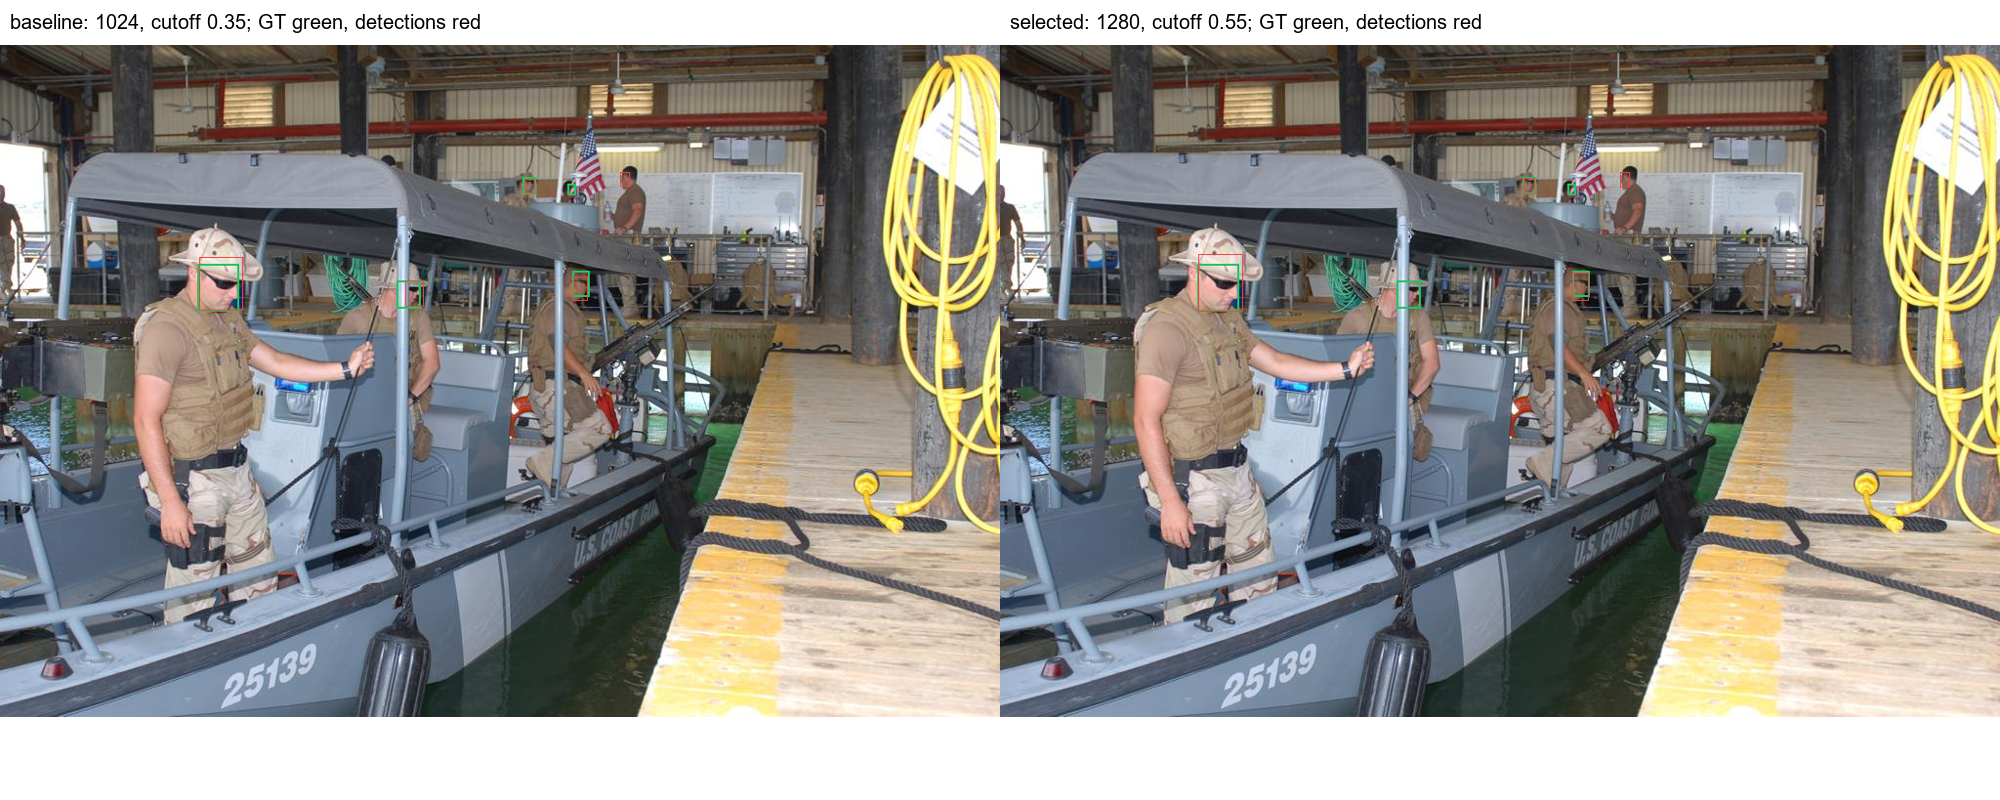

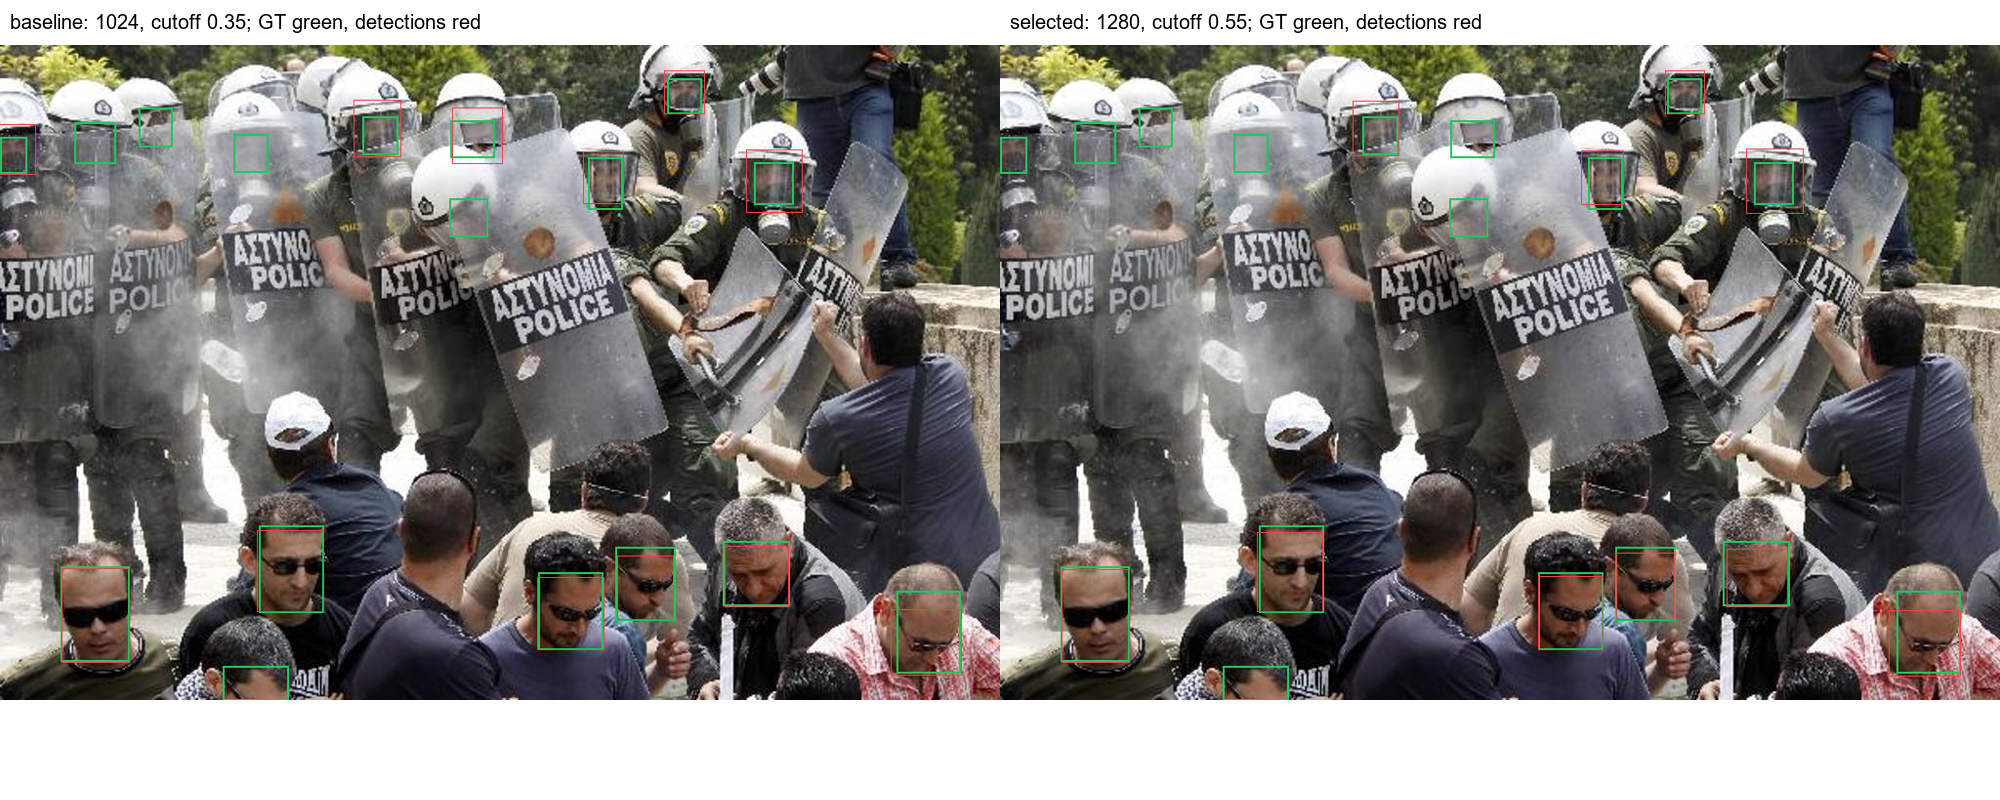

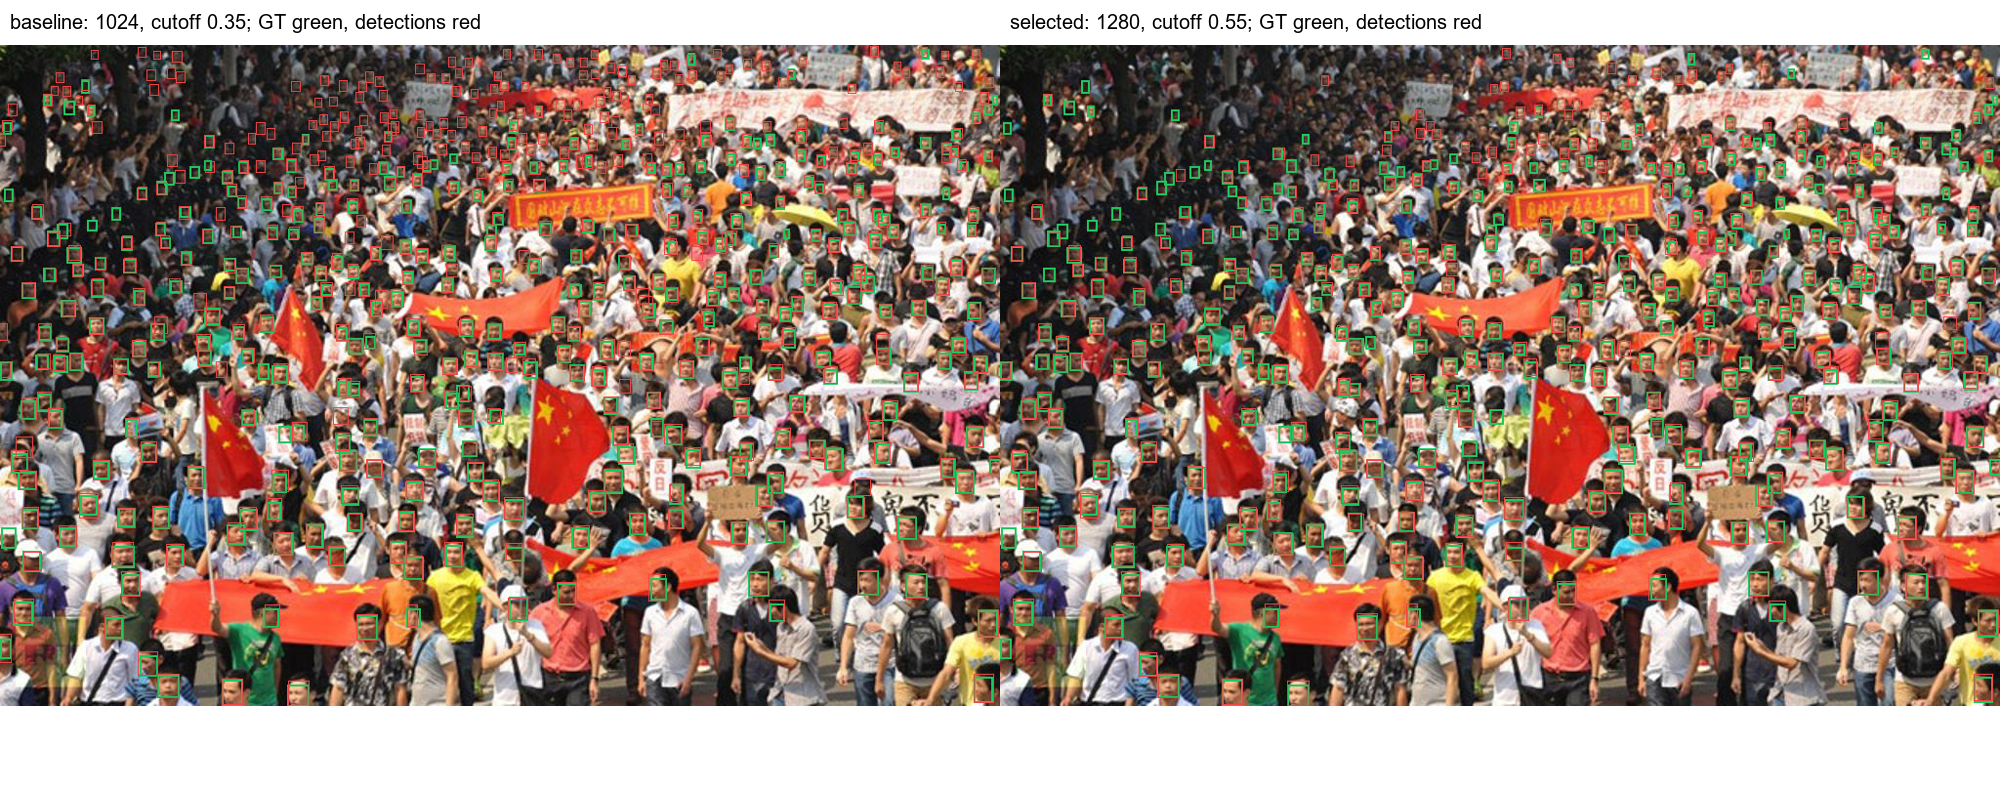

In [5]:
for path in sorted((RESULTS / 'example_overlays').glob('*.png')):
    display(Image(filename=str(path)))

## Reproducibility

Raw images and predictions stay under ignored `data/`. Report artifacts, evaluation source and the notebook can be shared separately. See `docs/widerface_benchmark.md` for the AP conventions, annotation anomalies and split limitations.

In [6]:
repro = json.loads((RESULTS / 'reproducibility.json').read_text())
print('Failures:', repro['failures'])
print('AP evaluator:', repro['ap_evaluator'])
print('Timing limit:', repro['timing_limit'])
print('Prediction checksums:', repro['predictions_sha256'])

Failures: 0
AP evaluator: NumPy port of supplied MATLAB: official masks, inclusive IoU 0.5, global score normalization, 1000 thresholds, VOC precision envelope
Timing limit: Cache timings at floor 0.02 shared across thresholds; exclude embeddings, redaction, cloud; no exact deployed-threshold latency claim
Prediction checksums: {'640': '754a564becf51eff1221e6b989ff2c6782029556990b7162cd132d4f620959e7', '1024': 'ff42b5a1461ada68942d5944bde778591647c654e923f9e9e4bf68a5ec8a5421', '1280': '902a5c9e261bebe8fbeb7bb26614c72c31a822b7d56b07453ac2e030f1567cc8'}


## Why individual detections failed

See [the illustrated error report](../reports/widerface/error_analysis/report.md) for zoomed cases with exact scores and overlap. These are post-hoc diagnostic examples, not an independent validation. Reproduce with:

```powershell
& .venv/Scripts/python.exe src/scripts/analyze_widerface_errors.py
```
